# Active subspaces of a viscous transonic airfoil: drag and pitching moment of the RAE 2822 with 20 Hicks–Henne bumps

Data from: P. S. Palar¹, Y. B. Dwianto¹, L. R. Zuhal¹, J. Morlier², K. Shimoyama³, S. Obayashi⁴, "Multi-objective design space exploration using explainable surrogate models", *Structural and Multidisciplinary Optimization* 67(3):38 (2024), [doi:10.1007/s00158-024-03769-z](https://doi.org/10.1007/s00158-024-03769-z).

¹ Faculty of Mechanical and Aerospace Engineering, Institut Teknologi Bandung, Bandung, Indonesia
² ICA, Université de Toulouse, ISAE–SUPAERO, INSA, CNRS, MINES ALBI, UPS, Toulouse, France
³ Department of Mechanical Engineering, Kyushu University, Fukuoka, Japan
⁴ Institute of Fluid Science, Tohoku University, Sendai, Japan

Notebook: Claude (Anthropic) for P. Constantine, 2026

## Summary

Palar et al. ran the open-source SU2 RANS solver (Spalart–Allmaras) on 98 shapes of the RAE 2822 airfoil, each perturbed by 20 Hicks–Henne bumps, at Mach 0.729 and fixed lift coefficient 0.723, and recorded the drag coefficient $C_d$ and the absolute quarter-chord moment $|C_m|$; they posted the runs with their code. With 98 runs for 20 inputs and no gradients, this notebook estimates one direction per output by ordinary least squares, checks it with gradients of a ridge-penalized quadratic, and tests a second direction against a null of a one-dimensional function plus noise and with a bootstrap that refits the quadratic. $|C_m|$ is almost exactly a linear function of one direction (leave-one-out $R^2$ 0.994); $C_d$ has a leading direction on the upper surface near $x_3$, $x_4$ that leaves about a third of its variance to a linear fit, and a second direction led by the trailing-edge bump $x_{20}$, whose curvature the runs support as the paper's p. 18 states, so this notebook takes two dimensions for $C_d$.

## Active subspaces in brief

For a function $f(\mathbf{x})$ of $m$ inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf{C} = \int \nabla f\, \nabla f^\top \rho\, d\mathbf{x} = \mathbf{W}\Lambda\mathbf{W}^\top$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along $\mathbf{W}_1^\top\mathbf{x}$, and a plot of $f$ against these active variables (a sufficient summary plot) shows the structure. Without gradients, a global linear fit $f \approx u_0 + \mathbf{u}^\top\mathbf{x}$ gives the one-dimensional estimate $\mathbf{w}_1 = \mathbf{u}/\lVert\mathbf{u}\rVert$; gradients of a fitted surrogate give an estimate of the whole matrix. See P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM (2015), [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

## The model

**Flow and geometry** (Sec. 4.2, pp. 16–17). Viscous transonic flow around the RAE 2822 airfoil, solved by SU2 with the Reynolds-averaged Navier–Stokes equations and the Spalart–Allmaras turbulence model at Mach 0.729 and fixed $C_l = 0.723$ (the solver adjusts the angle of attack to meet the lift). One run takes about 20 min of wall-clock time (p. 17). The paper does not give the Reynolds number, mesh or convergence criteria. The shape is the baseline ordinate plus Hicks–Henne bumps (Eqs. 19–20, p. 16):

$$\bar y_c = y_{c,\mathrm{base}} + \sum_{i=1}^{k} c_i \sin^{w_i}\!\left(\pi x_c^{v_i}\right), \qquad v_i = \frac{\ln 0.5}{\ln x_{J_i}},$$

with $x_{J_i}$ the location of the maximum of bump $i$ and width $w_i = 3$ for every bump. The maxima are set "from $x_{J1}$ to $x_{J10}$ in a step of 0.05" (p. 16; the first location is not stated). Ten bumps sit on the upper surface ($x_1$–$x_{10}$) and their mirrors on the lower surface ($x_{11}$–$x_{20}$); $x_1$ and $x_{11}$ are at the leading edge and $x_{20}$ is the lower-surface bump closest to the trailing edge (pp. 17–18). Positive amplitudes make the airfoil thicker on either surface (p. 17).

**Inputs** (m = 20; p. 17). The design variables are the bump amplitudes $x_i = c_i$:

| inputs | surface | units | range | source |
|---|---|---|---|---|
| $x_1, \dots, x_{10}$ | upper, leading edge to aft | fraction of chord | $[-0.003, 0.003]$ | Sec. 4.2, p. 17; Fig. 16 |
| $x_{11}, \dots, x_{20}$ | lower (mirror of the upper bumps) | fraction of chord | $[-0.003, 0.003]$ | Sec. 4.2, p. 17; Fig. 16 |

The authors' script normalizes the amplitudes to $[-1, 1]^{20}$ (`SHAP_Airfoil_viscous.m`), and so does this notebook (each amplitude divided by 0.003); the input space is uniform on the box. The unit "fraction of chord" is this data set's reading of the amplitudes as ordinate increments of a unit-chord airfoil.

**Quantities of interest** (p. 17). Drag coefficient $C_d$ and absolute pitching-moment coefficient about the quarter chord $|C_m|$, both to be minimized; dimensionless. The lift coefficient is held at 0.723, so it is not an output.

**Design.** The paper does not state how the 98 shapes were sampled. In the file the normalized coordinates all lie on a lattice of spacing 1/128 of the range, each input takes 98 distinct levels, and the first row is the centre of the box (the baseline RAE 2822). That pattern is consistent with an unscrambled Sobol'-type sequence on 128 levels starting at its second point (the first column runs 0.5, 0.75, 0.25, 0.375, … of the unit range); it is not scipy's unscrambled Sobol' sequence, whose first points agree but which diverges later. MATLAB's `sobolset` is a plausible, unverified source. Whether runs were dropped is not known.

In [1]:
%matplotlib inline
import warnings
import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac

SEED = 275
# OLS on a uniform space issues a ValidityWarning (its linearity condition holds only in special cases);
# the notebook discusses this in the text and checks the direction with a second estimator.
warnings.filterwarnings('ignore', category=ac.ValidityWarning)
np.set_printoptions(precision=4, suppress=False, linewidth=110)

## Load data

The two CSV files are the arrays `X` and `ff` of the authors' `Airfoil_Viscous_data.mat`, copied value for value by `convert_data.py`.

In [2]:
X = np.loadtxt('rae2822_hh_inputs.csv', delimiter=',')     # Hicks-Henne amplitudes c1..c20, fraction of chord
F = np.loadtxt('rae2822_hh_outputs.csv', delimiter=',')    # columns: Cd, |Cm|
names = [f'x{i}' for i in range(1, 21)]
qois = ['Cd', '|Cm|']
M, m = X.shape
space = ac.Uniform(-0.003 * np.ones(m), 0.003 * np.ones(m), names=names)
Z = X / 0.003                                             # normalized coordinates in [-1, 1]^20
print('X', X.shape, ' F', F.shape)
print('input range: [%.6f, %.6f]' % (X.min(), X.max()))
for j, q in enumerate(qois):
    print(f'{q:5s} min {F[:, j].min():.6f}  max {F[:, j].max():.6f}  mean {F[:, j].mean():.6f}')

X (98, 20)  F (98, 2)
input range: [-0.002953, 0.002953]
Cd    min 0.010951  max 0.021616  mean 0.014767
|Cm|  min 0.059070  max 0.121953  mean 0.091897


A few checks that the file holds a genuine design and genuine flow results:

In [3]:
k = (X + 0.003) / 0.006 * 128
print('largest distance of 128*u from an integer:', '%.1e' % np.abs(k - np.round(k)).max())
print('distinct levels per input:', sorted(set(len(np.unique(np.round(k[:, j]))) for j in range(m))))
print('row 1 at the centre (baseline RAE 2822):', bool(np.allclose(X[0], 0, atol=1e-18)),
      ' Cd = %.6f, |Cm| = %.6f' % tuple(F[0]))
print('duplicated rows:', M - len(np.unique(X, axis=0)))
print('x1 in the first 8 rows, as a fraction of its range:', np.round((X[:8, 0] + 0.003) / 0.006, 4))
print('correlation of Cd and |Cm|: %.3f' % np.corrcoef(F.T)[0, 1])

largest distance of 128*u from an integer: 1.4e-14
distinct levels per input: [98]
row 1 at the centre (baseline RAE 2822): True  Cd = 0.013427, |Cm| = 0.092877
duplicated rows: 0
x1 in the first 8 rows, as a fraction of its range: [0.5    0.75   0.25   0.375  0.875  0.625  0.125  0.1875]
correlation of Cd and |Cm|: -0.016


All coordinates sit on the 1/128 lattice to within about $10^{-14}$, no row repeats, and every input takes 98 distinct levels. The first row is the unperturbed RAE 2822 with $C_d$ = 0.013427 and $|C_m|$ = 0.092877, plausible values for this transonic condition; the 98 values span $C_d$ 0.010951–0.021616 and $|C_m|$ 0.059070–0.121953, the axis ranges of the paper's Figs. 17a and 18a (pp. 18–19). The two outputs are uncorrelated across the design (correlation −0.016).

## Estimate the subspace

There are no gradients: the paper's activity scores were computed from gradients of PC-Kriging surrogates (Appendix 1, p. 23), and the SU2 runs are not available here. With $M = 98$ runs and $m = 20$ inputs, a quadratic fit has 231 coefficients, more than the 98 runs, so the quadratic-model estimator (QPHD) is not possible; local linear gradients would use 34 of the 98 points per fit, which in 20 dimensions spans most of the design, so they add little to a global fit. The estimator is therefore **ordinary least squares** (OLS) for each output: $\mathbf{w}_1 = \mathbf{u}/\lVert\mathbf{u}\rVert$ from the linear fit in normalized coordinates, with $\lambda_1 = \lVert\mathbf{u}\rVert^2$. OLS gives one direction and no second eigenvalue. On a uniform box its direction equals the average gradient direction only for special functions, so the direction is checked below against gradients of a ridge-penalized quadratic, which also gives eigenvalue ratios. Uncertainty: 200 bootstrap replicates (rows resampled), and a permutation null of 500 shuffles of the output. Signs follow the paper's sufficient summary plots: $C_d$ increases along $\mathbf{w}_1$ (Fig. 17a, p. 18) and $|C_m|$ decreases along it (Fig. 18a, p. 19).

In [4]:
def loo_r2_linear(Zn, f):
    """Leave-one-out R^2 of the least-squares fit f ~ 1 + z (each fold refits the direction)."""
    A = np.c_[np.ones(len(f)), Zn]
    H = A @ np.linalg.pinv(A)
    r = (f - H @ f) / (1 - np.diag(H))
    return 1 - np.sum(r**2) / np.sum((f - f.mean())**2)

ols = {}
for j, q in enumerate(qois):
    sub = ac.active_subspace(space=space, X=X, f=F[:, j], estimator='ols', n=1, nboot=200, bootstrap_vectors=1,
                             rng=SEED, qoi=q)
    ols[q] = sub
# Signs as in the paper's Figs. 17a and 18a: Cd increases along w1 (x4 weight > 0);
# |Cm| decreases along w1 (x20 weight > 0).
ref = np.zeros((m, 1)); ref[3] = 1.0
ols['Cd'] = ac.orient(ols['Cd'], by='reference', reference=ref)
ref = np.zeros((m, 1)); ref[19] = 1.0
ols['|Cm|'] = ac.orient(ols['|Cm|'], by='reference', reference=ref)
for j, q in enumerate(qois):
    sub = ols[q]
    lo, hi = ac.bootstrap_interval(sub.bootstrap_eigenvalues[:, :1])[:, 0]
    d = sub.bootstrap_distances[:, 0]
    print(f'{q}: lambda1 = |u|^2 = {sub.eigenvalues[0]:.3e}  (95% bootstrap {lo:.3e} to {hi:.3e})')
    print(f'      bootstrap subspace distance of w1: median {np.median(d):.3f}, 95th pct {np.quantile(d, 0.95):.3f}')
    print(f'      LOO R^2 of the linear fit: {loo_r2_linear(Z, F[:, j]):.3f}')
    w = sub.W1[:, 0]
    top = np.argsort(-np.abs(w))[:6]
    print('      largest |w1| entries:', ', '.join(f'{names[i]} {w[i]:+.3f}' for i in top))

Cd: lambda1 = |u|^2 = 1.794e-05  (95% bootstrap 1.509e-05 to 2.459e-05)
      bootstrap subspace distance of w1: median 0.249, 95th pct 0.366
      LOO R^2 of the linear fit: 0.670
      largest |w1| entries: x4 +0.559, x3 +0.543, x7 -0.338, x5 +0.273, x8 -0.242, x2 +0.204
|Cm|: lambda1 = |u|^2 = 4.244e-04  (95% bootstrap 4.101e-04 to 4.423e-04)
      bootstrap subspace distance of w1: median 0.034, 95th pct 0.047
      LOO R^2 of the linear fit: 0.994
      largest |w1| entries: x20 +0.488, x19 +0.296, x5 -0.275, x6 -0.274, x4 -0.268, x18 +0.266


In [5]:
rng = np.random.default_rng(SEED)
nperm = 500
A = np.c_[np.ones(M), Z]
for j, q in enumerate(qois):
    f = F[:, j]
    lam_null, loo_null = np.empty(nperm), np.empty(nperm)
    for b in range(nperm):
        fp = rng.permutation(f)
        u = np.linalg.lstsq(A, fp, rcond=None)[0][1:]
        lam_null[b] = u @ u
        loo_null[b] = loo_r2_linear(Z, fp)
    print(f'{q}: lambda1 {ols[q].eigenvalues[0]:.3e}; permutation null 99th pct {np.quantile(lam_null, 0.99):.3e}'
          f'  (ratio {ols[q].eigenvalues[0] / np.median(lam_null):.1f} x the null median)')
    print(f'      LOO R^2 {loo_r2_linear(Z, f):.3f}; null LOO R^2 median {np.median(loo_null):.3f}, '
          f'99th pct {np.quantile(loo_null, 0.99):.3f}')
    # expected noise part of |u|^2 at the residual variance of the linear fit: s^2 tr[(A^T A)^-1] (slope block)
    r = f - A @ np.linalg.lstsq(A, f, rcond=None)[0]
    s2 = r @ r / (M - m - 1)
    noise = s2 * np.trace(np.linalg.inv(A.T @ A)[1:, 1:])
    print(f'      noise part of |u|^2 expected at the residual variance: {noise:.2e} '
          f'({100 * noise / ols[q].eigenvalues[0]:.1f} % of lambda1)')

Cd: lambda1 1.794e-05; permutation null 99th pct 9.028e-06  (ratio 3.8 x the null median)
      LOO R^2 0.670; null LOO R^2 median -0.301, 99th pct -0.043
      noise part of |u|^2 expected at the residual variance: 1.26e-06 (7.0 % of lambda1)


|Cm|: lambda1 4.244e-04; permutation null 99th pct 1.888e-04  (ratio 4.2 x the null median)
      LOO R^2 0.994; null LOO R^2 median -0.291, 99th pct -0.040
      noise part of |u|^2 expected at the residual variance: 4.96e-07 (0.1 % of lambda1)


## Results

**OLS directions.** For $|C_m|$ the linear fit has leave-one-out $R^2$ 0.994 and the bootstrap moves $\mathbf{w}_1$ little (median subspace distance 0.034). For $C_d$ the fit is much weaker, leave-one-out $R^2$ 0.670, and the direction is less certain (median distance 0.249, 95th percentile 0.366). Both are far from the permutation null: shuffled outputs give leave-one-out $R^2$ at most −0.043 ($C_d$) and −0.040 ($|C_m|$) at the 99th percentile, and $\lambda_1$ is 3.8 and 4.2 times the null median. The permutation null tests "no signal at all": it assigns the whole output variance to noise, so its $\lambda_1$ is bounded by the output variance and those ratios are weak statistics; the leave-one-out comparison is the informative one. At the actual residual variance $s^2$ of the linear fit, the expected noise part of $\lVert\mathbf{u}\rVert^2$, $s^2\,\mathrm{tr}[(A^\top A)^{-1}]$ over the slope block, is 1.26e-06 (7.0 % of $\lambda_1$) for $C_d$ and 4.96e-07 (0.1 %) for $|C_m|$.

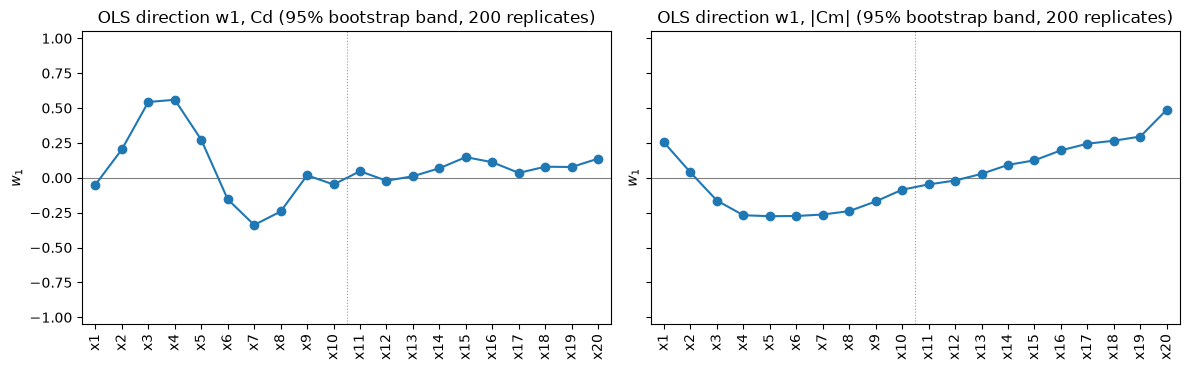

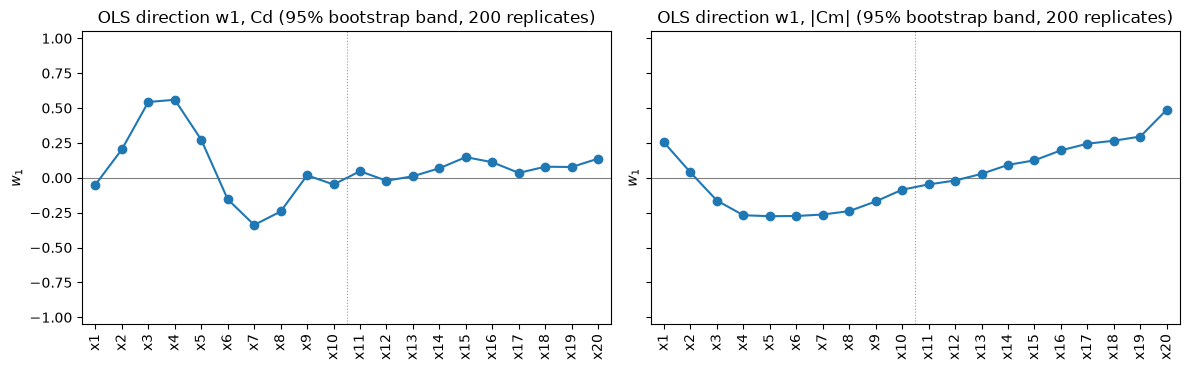

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, q in zip(axs, qois):
    ac.plotting.plot_eigenvectors(ols[q], indices=[0], labels=names, ax=ax)
    ax.set_title(f'OLS direction w1, {q} (95% bootstrap band, 200 replicates)')
    ax.axvline(10.5, color='0.6', lw=0.8, ls=':')
fig.tight_layout()
fig

The $C_d$ direction is concentrated on the upper surface: $x_4$ (+0.559) and $x_3$ (+0.543) raise drag, $x_7$ (−0.338) and $x_8$ (−0.242) lower it, and the lower-surface weights are all small. The $|C_m|$ direction is smooth along each surface: the aft lower-surface bumps ($x_{20}$ +0.488, $x_{19}$ +0.296, $x_{18}$ +0.266) reduce $|C_m|$ and the middle upper-surface bumps ($x_4$–$x_6$, about −0.27 each) increase it, with the sign change between $x_2$ and $x_3$ (and $x_{12}$, $x_{13}$) that the paper ties to the bumps' positions relative to the quarter chord (p. 18).

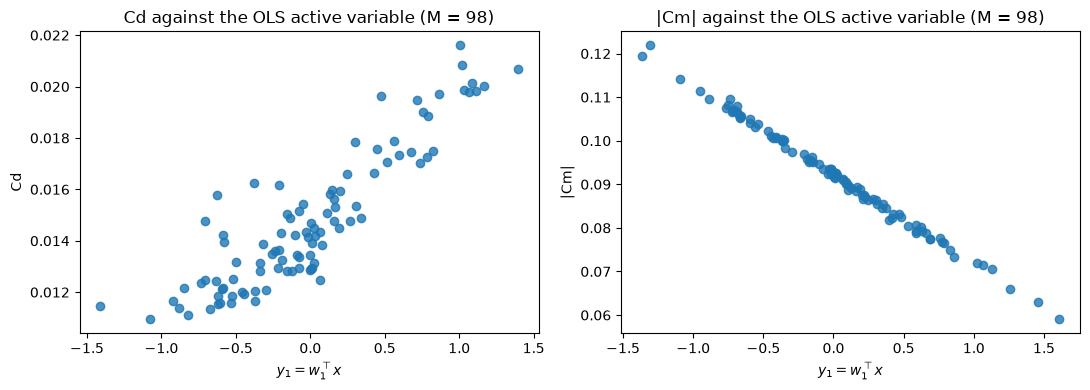

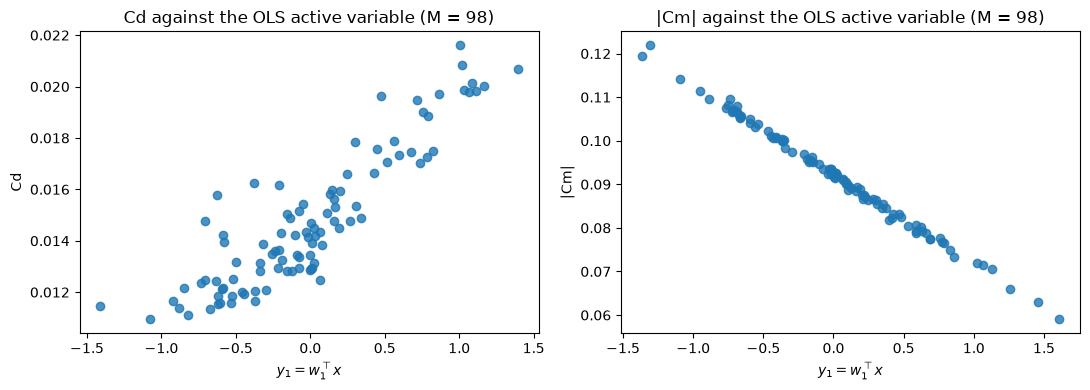

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, j, q in zip(axs, range(2), qois):
    ac.plotting.plot_sufficient_summary(ols[q], X=X, f=F[:, j], qoi_label=q, ax=ax)
    ax.set_title(f'{q} against the OLS active variable (M = {M})')
fig.tight_layout()
fig

The $|C_m|$ plot is a thin line, the same picture as the paper's Fig. 18a. The $C_d$ plot shows a clear trend with wide scatter at fixed active variable. The paper's Fig. 17a (p. 18) plots the same runs (about 98 markers, $C_d$ 0.011–0.022) against the direction $\mathbf{w}_1$ of its PC-Kriging surrogate and describes a "valley of minimum" (p. 17); in the figure the valley is weak, with the lowest values near $\mathbf{w}_1^\top\mathbf{x} \approx -1$ and a single point near −2. The linear direction here shows no valley.

### A check with surrogate gradients and a second direction

A full quadratic in the 20 normalized inputs is fitted with a ridge penalty on its 210 second-order coefficients only (231 coefficients from 98 runs, so the quadratic part is determined by the penalty as much as by the data). Its gradients at the 98 runs give an estimate of $\mathbf{C}$. The leave-one-out $R^2$ is exact for this linear smoother.

In [8]:
iu = np.triu_indices(m)

def quad_design(Zn):
    return np.c_[np.ones(len(Zn)), Zn, np.array([np.outer(z, z)[iu] for z in Zn])]

def ridge_quadratic(Zn, f, pen):
    """Quadratic fit with a ridge penalty on the 210 second-order coefficients only."""
    Q = quad_design(Zn)
    P = pen * np.eye(Q.shape[1]); P[:m + 1, :m + 1] = 0.0
    S = np.linalg.solve(Q.T @ Q + P, Q.T)
    H = Q @ S
    c = S @ f
    r = (f - H @ f) / (1 - np.diag(H))
    loo = 1 - np.sum(r**2) / np.sum((f - f.mean())**2)
    B = np.zeros((m, m)); B[iu] = c[m + 1:]
    G = c[1:m + 1] + Zn @ (B + B.T)          # gradients in normalized coordinates
    return loo, G

pens = [1e-3, 1e-2, 1e-1, 1.0, 10.0]
rq = {}
for j, q in enumerate(qois):
    print(q)
    for pen in pens:
        loo, G = ridge_quadratic(Z, F[:, j], pen)
        lam = np.linalg.eigvalsh(G.T @ G / M)[::-1]
        print(f'   penalty {pen:6.0e}: LOO R^2 {loo:.3f}   lambda1/lambda2 {lam[0] / lam[1]:7.1f}'
              f'   lambda2/lambda3 {lam[1] / lam[2]:5.2f}   lambda3/lambda4 {lam[2] / lam[3]:5.2f}')
        rq[(q, pen)] = (loo, G)

Cd
   penalty  1e-03: LOO R^2 0.859   lambda1/lambda2    11.2   lambda2/lambda3  2.70   lambda3/lambda4  1.28
   penalty  1e-02: LOO R^2 0.859   lambda1/lambda2    11.2   lambda2/lambda3  2.70   lambda3/lambda4  1.28
   penalty  1e-01: LOO R^2 0.858   lambda1/lambda2    11.4   lambda2/lambda3  2.74   lambda3/lambda4  1.28
   penalty  1e+00: LOO R^2 0.848   lambda1/lambda2    12.7   lambda2/lambda3  3.00   lambda3/lambda4  1.27
   penalty  1e+01: LOO R^2 0.809   lambda1/lambda2    23.4   lambda2/lambda3  3.56   lambda3/lambda4  1.30
|Cm|
   penalty  1e-03: LOO R^2 0.994   lambda1/lambda2   816.6   lambda2/lambda3  1.17   lambda3/lambda4  1.57
   penalty  1e-02: LOO R^2 0.994   lambda1/lambda2   820.5   lambda2/lambda3  1.17   lambda3/lambda4  1.57
   penalty  1e-01: LOO R^2 0.994   lambda1/lambda2   857.9   lambda2/lambda3  1.17   lambda3/lambda4  1.54
   penalty  1e+00: LOO R^2 0.995   lambda1/lambda2  1130.2   lambda2/lambda3  1.22   lambda3/lambda4  1.37
   penalty  1e+01: LOO R^2 0.

Over penalties from $10^{-3}$ to $10^{-1}$ the leave-one-out $R^2$ is flat (0.859–0.858 for $C_d$, 0.994 for $|C_m|$); this data set takes 0.1. The eigenvalue ratios depend on the penalty: for $C_d$, $\lambda_1/\lambda_2$ rises from 11.2 to 23.4 as the penalty grows to 10, because the penalty shrinks the curvature that feeds the later eigenvalues.

In [9]:
PEN = 0.1   # a penalty in the flat part of the LOO curve above (this data set's choice)
asq = {}
for j, q in enumerate(qois):
    G = rq[(q, PEN)][1] / 0.003            # physical-coordinate gradients for the space
    sub = ac.active_subspace(space=space, grads=G, estimator='as', n=1, nboot=200, rng=SEED, qoi=q)
    asq[q] = ac.orient(sub, by='reference', reference=ols[q].W1)
    lam = sub.eigenvalues
    print(f'{q}: first eigenvalues {lam[:4]}; ratios {np.round(lam[:3] / lam[1:4], 2)}')
    print(f'      left-out share sum(lambda_2..)/sum(lambda) = {lam[1:].sum() / lam.sum():.3f}')
    print(f'      |w1(OLS) . w1(ridge quadratic)| = {abs(ols[q].W1[:, 0] @ asq[q].W1[:, 0]):.3f}')
    lo, hi = ac.bootstrap_interval(sub.bootstrap_eigenvalues[:, :3])
    print('      95% bootstrap of lambda1..3:', ', '.join(f'[{a:.2e}, {b:.2e}]' for a, b in zip(lo, hi)))
    w2 = asq[q].eigenvectors[:, 1]
    print('      largest |w2| entries:', ', '.join(f'{names[i]} {w2[i]:+.3f}' for i in np.argsort(-np.abs(w2))[:5]))

Cd: first eigenvalues [1.8915e-05 1.6660e-06 6.0788e-07 4.7490e-07]; ratios [11.35  2.74  1.28]
      left-out share sum(lambda_2..)/sum(lambda) = 0.193
      |w1(OLS) . w1(ridge quadratic)| = 0.990
      95% bootstrap of lambda1..3: [1.78e-05, 2.03e-05], [1.02e-06, 2.35e-06], [4.81e-07, 8.83e-07]
      largest |w2| entries: x20 +0.579, x6 -0.378, x2 +0.369, x4 -0.315, x5 -0.242


|Cm|: first eigenvalues [4.3496e-04 5.0703e-07 4.3157e-07 2.7987e-07]; ratios [857.85   1.17   1.54]
      left-out share sum(lambda_2..)/sum(lambda) = 0.005
      |w1(OLS) . w1(ridge quadratic)| = 1.000
      95% bootstrap of lambda1..3: [4.30e-04, 4.39e-04], [4.30e-07, 6.97e-07], [3.26e-07, 5.04e-07]
      largest |w2| entries: x3 +0.609, x2 +0.434, x13 -0.327, x20 +0.307, x19 +0.204


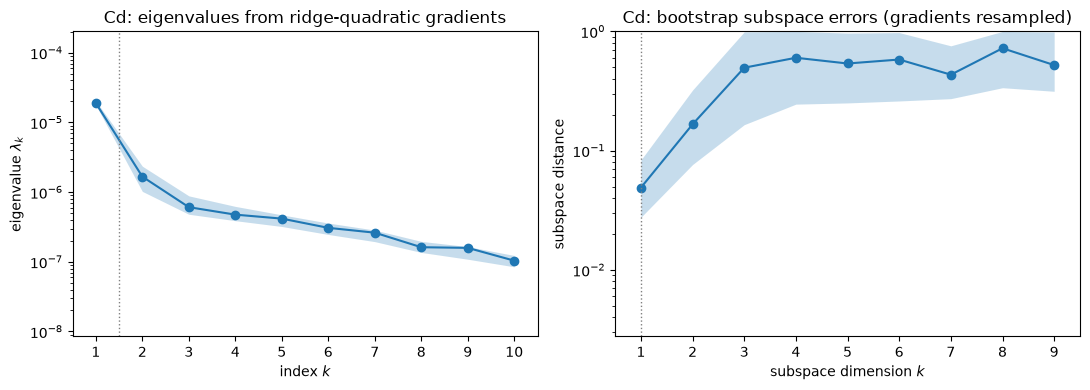

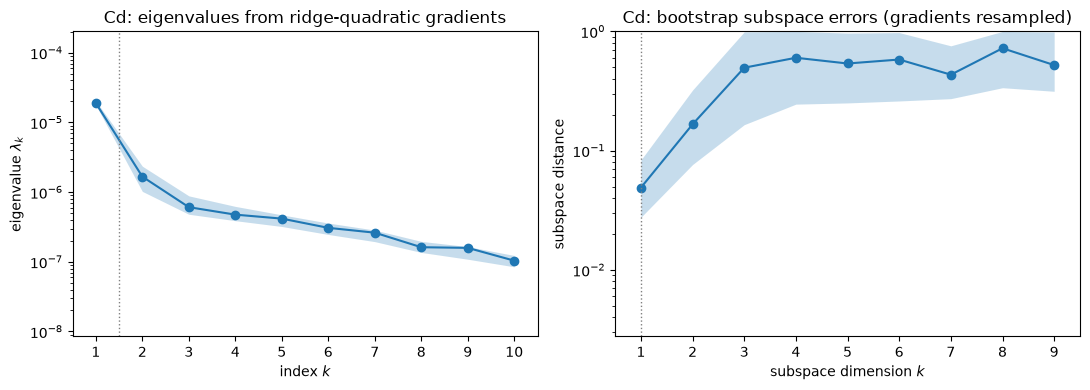

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
ac.plotting.plot_eigenvalues(asq['Cd'], k_max=10, ax=axs[0])
axs[0].set_title('Cd: eigenvalues from ridge-quadratic gradients')
ac.plotting.plot_subspace_errors(asq['Cd'], k_max=9, ax=axs[1])
axs[1].set_title('Cd: bootstrap subspace errors (gradients resampled)')
fig.tight_layout()
fig

The surrogate-gradient direction agrees with OLS ($|\mathbf{w}_1^{\mathrm{OLS}}\cdot\mathbf{w}_1| = 0.990$ for $C_d$ and 1.000 for $|C_m|$). For $|C_m|$, $\lambda_1/\lambda_2 = 857.85$ and the left-out share of the eigenvalue sum is 0.005: one dimension. For $C_d$, $\lambda_1/\lambda_2 = 11.35$, the next ratio is 2.74 and then 1.28, and the left-out share is 0.193. The second $C_d$ eigenvector is led by $x_{20}$ (+0.579), the bump the paper finds responsible for the nonlinearity of $C_d$ (p. 18). The bootstrap in this cell resamples the 98 fitted gradients and does not refit the quadratic, so its intervals understate the uncertainty; the refit bootstrap below gives the intervals to use.

### Is the second $C_d$ direction more than noise?

Two checks, 200 draws each, with the same ridge quadratic (penalty 0.1). (a) A null with a one-dimensional truth: the quadratic in the OLS active variable fitted to the runs, plus independent Gaussian noise with the sd of its residuals; each draw is analysed as the data are. (b) A refit bootstrap: rows resampled, the quadratic refitted, gradients taken at the resampled rows.

In [11]:
def rq_eig(Zn, f, pen=PEN):
    """Eigenpairs (descending) of the mean outer product of ridge-quadratic gradients at the rows Zn."""
    Q = quad_design(Zn)
    P = pen * np.eye(Q.shape[1]); P[:m + 1, :m + 1] = 0.0
    c = np.linalg.solve(Q.T @ Q + P, Q.T @ f)
    B = np.zeros((m, m)); B[iu] = c[m + 1:]
    G = c[1:m + 1] + Zn @ (B + B.T)
    lam, W = np.linalg.eigh(G.T @ G / len(f))
    return lam[::-1], W[:, ::-1]

NB = 200
rng = np.random.default_rng(SEED)
for j, q in enumerate(qois):
    f = F[:, j]
    lam_obs = asq[q].eigenvalues
    r_obs = lam_obs[:2] / lam_obs[1:3]
    # (a) null: a one-dimensional truth (quadratic in the OLS active variable) plus Gaussian noise
    y = Z @ ols[q].W1[:, 0]
    p = np.polyfit(y, f, 2)
    ftrue = np.polyval(p, y)
    s = np.std(f - ftrue, ddof=3)
    null_r, null_top = np.empty((NB, 2)), np.empty(NB, int)
    for b in range(NB):
        lam, W = rq_eig(Z, ftrue + s * rng.standard_normal(M))
        null_r[b] = lam[:2] / lam[1:3]
        null_top[b] = np.argmax(np.abs(W[:, 1]))
    # (b) refit bootstrap: rows resampled, quadratic refitted, gradients at the resampled rows
    boot_r, boot_top = np.empty((NB, 2)), np.empty(NB, int)
    for b in range(NB):
        idx = rng.integers(0, M, M)
        lam, W = rq_eig(Z[idx], f[idx])
        boot_r[b] = lam[:2] / lam[1:3]
        boot_top[b] = np.argmax(np.abs(W[:, 1]))
    print(f'{q}: observed lambda1/lambda2 {r_obs[0]:.2f}, lambda2/lambda3 {r_obs[1]:.2f}; noise sd of the null {s:.2e}')
    print(f'      1-D null ({NB} draws): lambda1/lambda2 median {np.median(null_r[:, 0]):.1f} '
          f'(95% range {np.quantile(null_r[:, 0], 0.025):.1f} to {np.quantile(null_r[:, 0], 0.975):.1f}); '
          f'lambda2/lambda3 median {np.median(null_r[:, 1]):.2f}, 95th pct {np.quantile(null_r[:, 1], 0.95):.2f}, '
          f'share >= observed {np.mean(null_r[:, 1] >= r_obs[1]):.3f}')
    print(f'      1-D null: x20 leads w2 in {np.sum(null_top == 19)} of {NB} draws; '
          f'distinct inputs leading w2: {len(np.unique(null_top))}')
    print(f'      refit bootstrap ({NB}): lambda1/lambda2 95% interval [{np.quantile(boot_r[:, 0], 0.025):.1f}, '
          f'{np.quantile(boot_r[:, 0], 0.975):.1f}], lambda2/lambda3 [{np.quantile(boot_r[:, 1], 0.025):.2f}, '
          f'{np.quantile(boot_r[:, 1], 0.975):.2f}]; x20 leads w2 in {np.sum(boot_top == 19)} of {NB}')

Cd: observed lambda1/lambda2 11.35, lambda2/lambda3 2.74; noise sd of the null 1.12e-03
      1-D null (200 draws): lambda1/lambda2 median 15.7 (95% range 7.7 to 29.2); lambda2/lambda3 median 1.31, 95th pct 1.88, share >= observed 0.000
      1-D null: x20 leads w2 in 6 of 200 draws; distinct inputs leading w2: 20
      refit bootstrap (200): lambda1/lambda2 95% interval [8.8, 40.3], lambda2/lambda3 [1.16, 4.22]; x20 leads w2 in 141 of 200


|Cm|: observed lambda1/lambda2 857.85, lambda2/lambda3 1.17; noise sd of the null 7.51e-04
      1-D null (200 draws): lambda1/lambda2 median 826.8 (95% range 448.3 to 1365.9); lambda2/lambda3 median 1.31, 95th pct 1.83, share >= observed 0.785
      1-D null: x20 leads w2 in 1 of 200 draws; distinct inputs leading w2: 20
      refit bootstrap (200): lambda1/lambda2 95% interval [809.9, 2512.2], lambda2/lambda3 [1.08, 2.43]; x20 leads w2 in 12 of 200


For $C_d$ the observed $\lambda_2/\lambda_3$ = 2.74 exceeds every one of the 200 null draws (null median 1.31, 95th percentile 1.88), and under the null the input that leads $\mathbf{w}_2$ is spread over all 20 inputs ($x_{20}$ in 6 of 200 draws), while in the refit bootstrap $x_{20}$ leads $\mathbf{w}_2$ in 141 of 200 replicates. The same null gives $\lambda_1/\lambda_2$ a median of 15.7 (95 % range 7.7 to 29.2), so the observed 11.35 is by itself no evidence of a one-dimensional gap: a one-dimensional truth with this noise gives such ratios. The refit bootstrap puts $\lambda_1/\lambda_2$ in [8.8, 40.3] and $\lambda_2/\lambda_3$ in [1.16, 4.22]. For $|C_m|$ the observed $\lambda_2/\lambda_3$ = 1.17 is below the null median (a share 0.785 of the null draws is at least as large): no second direction.

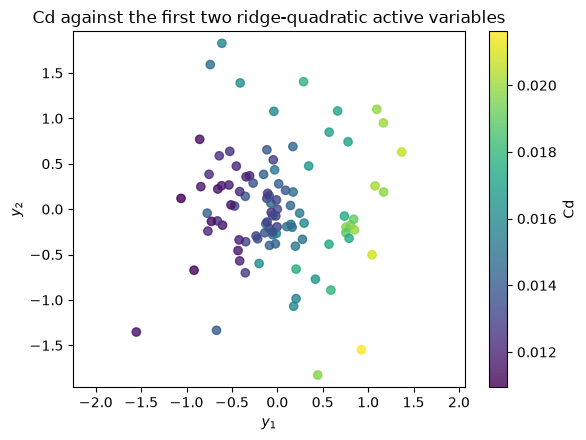

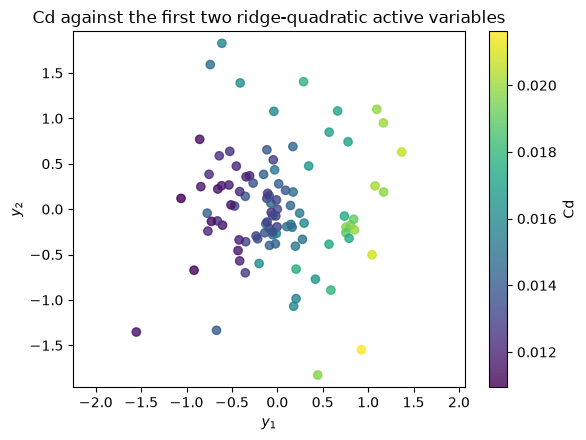

In [12]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ac.plotting.plot_sufficient_summary(asq['Cd'], X=X, f=F[:, 0], dims=2, qoi_label='Cd', ax=ax)
ax.set_title('Cd against the first two ridge-quadratic active variables')
fig.tight_layout()
fig

$C_d$ rises mainly with $y_1$; at fixed $y_1$ the largest drag values tend to sit at large $|y_2|$, the scatter that $y_1$ alone leaves.

**Dimension.** $|C_m|$: $n = 1$ (OLS leave-one-out $R^2$ 0.994; eigenvalue ratio 857.85; $\lambda_2/\lambda_3$ inside the one-dimensional null). $C_d$: $n = 2$. The second eigenvalue is larger than a one-dimensional truth with this noise produces ($\lambda_2/\lambda_3$ = 2.74 above all 200 null draws), its eigenvector is led by $x_{20}$ in most refit bootstraps, and the next ratio $\lambda_3/\lambda_4$ = 1.28 shows no further gap. The weights of $\mathbf{w}_2$ remain uncertain: the ratio depends on the penalty (2.70–3.56 over the grid), the 98 runs determine the 210 curvature coefficients only together with the penalty, and 19.3 % of the eigenvalue sum lies outside $\mathbf{w}_1$. The sign of $\mathbf{w}_2$ is as computed ($x_{20}$ weight positive).

## Surrogate on the active variable

In [13]:
def loo_quadratic_in_w1(Zn, f):
    """LOO R^2 of f ~ a + b y + c y^2, y = w1^T z, with w1 refitted by OLS in every fold."""
    err = np.empty(len(f))
    for i in range(len(f)):
        keep = np.arange(len(f)) != i
        A = np.c_[np.ones(keep.sum()), Zn[keep]]
        u = np.linalg.lstsq(A, f[keep], rcond=None)[0][1:]
        w = u / np.linalg.norm(u)
        y = Zn[keep] @ w
        c = np.polyfit(y, f[keep], 2)
        err[i] = f[i] - np.polyval(c, Zn[i] @ w)
    return 1 - np.sum(err**2) / np.sum((f - f.mean())**2)

for j, q in enumerate(qois):
    s = ac.fit_surrogate(X=X, f=F[:, j], subspace=ols[q], kind='poly', degree=2)
    print(f'{q}: quadratic in the OLS active variable: LOO R^2 {s.loo_r_squared:.3f} (direction fixed), '
          f'{loo_quadratic_in_w1(Z, F[:, j]):.3f} (direction refitted in each fold)')

Cd: quadratic in the OLS active variable: LOO R^2 0.821 (direction fixed), 0.726 (direction refitted in each fold)
|Cm|: quadratic in the OLS active variable: LOO R^2 0.996 (direction fixed), 0.994 (direction refitted in each fold)


A quadratic in $y_1 = \mathbf{w}_1^\top\mathbf{x}$ raises the $C_d$ leave-one-out $R^2$ from 0.670 (linear) to 0.821 if the direction is held fixed, but only to 0.726 when the direction is refitted in every fold, the honest figure. For $|C_m|$ the quadratic adds nothing (0.994 with the direction refitted). The gap between 0.726 and the full ridge quadratic's 0.858 is the part of $C_d$ that one direction does not capture.

Which input carries the curvature? A fit with the linear terms and one square per input (41 coefficients, ordinary least squares), and the linear fit plus the single term $z_{20}^2$:

In [14]:
def loo_r2_design(D, f):
    """Leave-one-out R^2 of the least-squares fit f ~ D (each fold refits)."""
    H = D @ np.linalg.pinv(D)
    r = (f - H @ f) / (1 - np.diag(H))
    return 1 - np.sum(r**2) / np.sum((f - f.mean())**2)

f = F[:, 0]
# Cd: linear terms plus one square per input, 41 coefficients, ordinary least squares
D = np.c_[np.ones(M), Z, Z**2]
c = np.linalg.lstsq(D, f, rcond=None)[0]
r = f - D @ c
se = np.sqrt(r @ r / (M - D.shape[1]) * np.diag(np.linalg.inv(D.T @ D)))
t = c[m + 1:] / se[m + 1:]
print('Cd, squares z_j^2 with the largest |t|:',
      ', '.join(f'{names[i]}^2 {c[m + 1 + i]:+.2e} (|t| {abs(t[i]):.1f})' for i in np.argsort(-np.abs(t))[:3]))
# Cd: linear fit plus the single term z20^2
D20 = np.c_[np.ones(M), Z, Z[:, 19]**2]
c20 = np.linalg.lstsq(D20, f, rcond=None)[0]
print(f'Cd, LOO R^2: linear {loo_r2_design(D20[:, :-1], f):.3f}, linear + z20^2 {loo_r2_design(D20, f):.3f}')
G20 = np.tile(c20[1:m + 1], (M, 1)); G20[:, 19] += 2 * c20[-1] * Z[:, 19]
a20 = np.mean(G20**2, axis=0)
print('      activity scores of linear + z20^2, top 4:', ', '.join(f'{names[i]} {a20[i]:.2e}' for i in np.argsort(-a20)[:4]))

Cd, squares z_j^2 with the largest |t|: x20^2 +2.67e-03 (|t| 3.2), x2^2 +1.31e-03 (|t| 2.9), x13^2 +6.96e-04 (|t| 1.6)
Cd, LOO R^2: linear 0.670, linear + z20^2 0.752
      activity scores of linear + z20^2, top 4: x20 7.19e-06, x4 5.55e-06, x3 5.12e-06, x5 1.49e-06


The square of $z_{20}$ has the largest coefficient of the 20 squares ($|t|$ = 3.2; next $z_2^2$, 2.9), and adding that one term to the linear fit raises the $C_d$ leave-one-out $R^2$ from 0.670 to 0.752, more than the quadratic in $y_1$ (0.726). In that model $x_{20}$ has the largest activity score, 7.19e-06, ahead of $x_4$ (5.55e-06) and $x_3$ (5.12e-06). The runs support the paper's statement that "the nonlinearity of $C_d$ is primarily due to $x_{20}$" (p. 18).

## Comparison with the paper

The paper's activity scores (Appendix 1, p. 23) sum $\lambda_i w_{j,i}^2$ over all $m$ eigenpairs, i.e. they are the diagonal of $\mathbf{C}$ in the normalized coordinates; the same quantity is computed here from the ridge-quadratic gradients and, for one direction, from OLS.

In [15]:
# The paper's activity scores (Appendix 1, p. 23) sum lambda_i w_{j,i}^2 over all m eigenpairs,
# i.e. the diagonal of C = mean of grad f grad f^T in [-1, 1]^20 coordinates.
for q in qois:
    G = rq[(q, PEN)][1]
    a_rq = np.mean(G**2, axis=0)
    a_ols = ols[q].eigenvalues[0] * ols[q].W1[:, 0]**2
    o1, o2 = np.argsort(-a_rq)[:5], np.argsort(-a_ols)[:5]
    print(f'{q}: ridge-quadratic scores, top 5:', ', '.join(f'{names[i]} {a_rq[i]:.2e}' for i in o1))
    print(f'      OLS scores (n = 1),     top 5:', ', '.join(f'{names[i]} {a_ols[i]:.2e}' for i in o2))
    print(f'      x20: ridge-quadratic score {a_rq[19]:.2e} (rank {int(np.sum(a_rq > a_rq[19])) + 1}), '
          f'OLS score {a_ols[19]:.2e} (rank {int(np.sum(a_ols > a_ols[19])) + 1})')

Cd: ridge-quadratic scores, top 5: x3 6.45e-06, x4 5.68e-06, x5 1.95e-06, x7 1.75e-06, x2 1.24e-06
      OLS scores (n = 1),     top 5: x4 5.62e-06, x3 5.30e-06, x7 2.05e-06, x5 1.33e-06, x8 1.05e-06
      x20: ridge-quadratic score 1.03e-06 (rank 6), OLS score 3.40e-07 (rank 9)
|Cm|: ridge-quadratic scores, top 5: x20 1.02e-04, x19 3.80e-05, x5 3.44e-05, x6 3.25e-05, x18 3.06e-05
      OLS scores (n = 1),     top 5: x20 1.01e-04, x19 3.71e-05, x5 3.21e-05, x6 3.18e-05, x4 3.05e-05
      x20: ridge-quadratic score 1.02e-04 (rank 1), OLS score 1.01e-04 (rank 1)


| quantity | paper (page) | this notebook |
|---|---|---|
| surrogate accuracy, $C_d$ | PC-Kriging LOOCV error 0.0631 (p. 17) | LOO $R^2$: linear 0.670, quadratic in $y_1$ 0.726, ridge quadratic 0.858 |
| surrogate accuracy, $|C_m|$ | PC-Kriging LOOCV error 9.6 × 10⁻³ (p. 17) | LOO $R^2$: linear 0.994, ridge quadratic 0.994 |
| eigenvalues, ratios | not reported | $C_d$ 11.35, 2.74; $|C_m|$ 857.85, 1.17 (ridge quadratic, penalty 0.1); $n$ = 2 ($C_d$), 1 ($|C_m|$) |
| one-dimensional structure, $C_d$ | not monotonic, a valley in the 1-D summary plot; "does not feature a strong one-dimensional active subspace" (p. 17, Fig. 17a) | monotonic trend with wide scatter along $\mathbf{w}_1$; a second direction led by $x_{20}$ passes a one-dimensional null |
| one-dimensional structure, $|C_m|$ | monotonic, "extremely close to linear" (p. 17, Fig. 18a) | linear, LOO $R^2$ 0.994 |
| sign of the trend | $C_d$ rises, $|C_m|$ falls along $\mathbf{w}_1$ (Figs. 17a, 18a) | the same (set by orientation) |
| leading inputs, $C_d$ | $x_3$ and $x_4$, "followed by $x_{20}$ or $x_5$" (p. 17) | ridge quadratic: $x_3$, $x_4$, $x_5$, $x_7$, $x_2$, $x_{20}$ 6th; linear + $z_{20}^2$: $x_{20}$, $x_4$, $x_3$, $x_5$ |
| activity scores, $C_d$ | about 0.72 × 10⁻⁵ ($x_4$), 0.59 × 10⁻⁵ ($x_3$), 0.42 × 10⁻⁵ ($x_{20}$, 3rd), 0.30 × 10⁻⁵ ($x_5$) (read from Fig. 17b, p. 18) | ridge quadratic: 6.45e-06 ($x_3$), 5.68e-06 ($x_4$), 1.03e-06 ($x_{20}$); linear + $z_{20}^2$: 7.19e-06 ($x_{20}$), 5.55e-06 ($x_4$), 5.12e-06 ($x_3$) |
| source of the $C_d$ nonlinearity | "primarily due to $x_{20}$" (SHAP dependence plot, p. 18) | $z_{20}^2$ the largest square ($|t|$ 3.2); linear + $z_{20}^2$ LOO $R^2$ 0.752 vs 0.670; $x_{20}$ leads $\mathbf{w}_2$ |
| leading inputs, $|C_m|$ | $x_{20}$ largest, then $x_{19}$ (Fig. 18b) | $x_{20}$, $x_{19}$, $x_5$, $x_6$, $x_{18}$ |
| largest activity score, $|C_m|$ | about 1.0 × 10⁻⁴ for $x_{20}$ (read from Fig. 18b) | 1.02e-04 ($x_{20}$) |

UQLab's LOOCV error is a relative mean squared error, so the paper's values correspond to leave-one-out $R^2$ = 1 − 0.0631 ($C_d$) and 1 − 0.0096 ($|C_m|$). The PC-Kriging surrogate fits $C_d$ better than any model here. The runs support the paper's $x_{20}$ curvature: the low $x_{20}$ rank in the ridge-quadratic scores comes from the estimator, whose single penalty on 210 second-order terms spreads the $x_{20}$ curvature over cross terms, while a model with the one square $z_{20}^2$ ranks $x_{20}$ first and fits better. Activity-score ranks of $x_3$, $x_4$ and $x_{20}$ therefore depend on the surrogate, and the paper's order (Fig. 17b) lies between the two models here. Both analyses agree on the $|C_m|$ direction, on $x_3$, $x_4$ as main drag inputs and on $x_{20}$ as the source of the $C_d$ nonlinearity. Whether the valley in Fig. 17a comes from the $x_{20}$ curvature is not known.

## References

- P. S. Palar, Y. B. Dwianto, L. R. Zuhal, J. Morlier, K. Shimoyama, S. Obayashi. Multi-objective design space exploration using explainable surrogate models. *Structural and Multidisciplinary Optimization* 67(3):38, 2024. [doi:10.1007/s00158-024-03769-z](https://doi.org/10.1007/s00158-024-03769-z). Code and data: [github.com/optimuspram/SHAPMODE](https://github.com/optimuspram/SHAPMODE).
- P. G. Constantine. *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*. SIAM, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).
- P. G. Constantine, P. Diaz. Global sensitivity metrics from active subspaces. *Reliability Engineering & System Safety* 162:1–13, 2017. [doi:10.1016/j.ress.2017.01.013](https://doi.org/10.1016/j.ress.2017.01.013).
- R. M. Hicks, P. A. Henne. Wing design by numerical optimization. *Journal of Aircraft* 15(7):407–412, 1978. [doi:10.2514/3.58379](https://doi.org/10.2514/3.58379).
- T. D. Economon, F. Palacios, S. R. Copeland, T. W. Lukaczyk, J. J. Alonso. SU2: an open-source suite for multiphysics simulation and design. *AIAA Journal* 54(3):828–846, 2016. [doi:10.2514/1.J053813](https://doi.org/10.2514/1.J053813).

## Acknowledgments

From the paper (p. 23): P. S. Palar, L. R. Zuhal and Y. B. Dwianto acknowledge financial support from Institut Teknologi Bandung under the Riset Unggulan ITB; part of the work was carried out under the Collaborative Research Project 2023 of the Institute of Fluid Science, Tohoku University.